# 1. 연구 개요
# Evaluation of Sampling and Interpolation Methods for Compressing Sorted Sentence Embeddings

**연구 질문:** 문장 임베딩을 정렬하고 일부 좌표만 저장한 뒤 보간할 때 샘플링 방법, 보간법, 샘플 수에 따라 복원 정확도와 실제 저장량은 어떻게 달라지는가?

**파이프라인:** 원본 float32 임베딩 → 전체 오름차순 정렬 → 샘플 값·인덱스·순열 저장 → 보간 → 역정렬 → 원본과 같은 차원 순서에서 평가.

한국어 50개와 영어 50개의 짧은 문장을 사용한다. 주 실험은 Uniform/Chebyshev-Lobatto × Linear/Natural Cubic Spline × 8개 샘플 수의 32개 조건이다. **원본 차원 순서 + Uniform + Linear**를 8개 대조 조건으로 추가한다. 문장 간 표준편차는 데이터 내 변동이며 신뢰구간이나 독립 반복 실험의 표준오차가 아니다.

### 실행 방법
1. Python 3.10 이상 Jupyter/VS Code 커널에 필요한 패키지를 설치한다. 필요하면 아래 명령을 임시 셀에서 한 번 실행한다.
   `%pip install numpy scipy pandas matplotlib sentence-transformers ipykernel`
2. 아래 설정을 확인한 뒤 **Run All**로 순서대로 실행한다. 기본값은 실제 모델, CPU 실행이다. 첫 실행은 모델 다운로드 때문에 오래 걸릴 수 있고, 이후에는 .npy 캐시를 사용한다.
3. 인터넷/모델 설치가 어려우면 `DATA_MODE = "synthetic"`로 바꾼다. 이 모드는 정규분포 난수로 수치 코드만 시험하며 **문장 임베딩 연구 결과로 사용하지 않는다**. 자동 대체도 명시적으로 허용해야 한다.
4. 실제 결과는 `results/`, 합성 테스트는 `results/synthetic/`에 저장된다. 같은 모드 재실행은 결과 파일을 갱신한다.

**해석 범위:** 정렬은 좌표값을 매끄럽게 보이게 만드는 수치적 전처리이다. 좌표 간 의미적 연속성, 검색 성능 또는 다른 모델로의 일반화를 입증하지 않는다. Cubic Spline은 단조성을 보장하지 않으므로 clipping이나 재정렬으로 결과를 보정하지 않는다.


## 2. 라이브러리 및 실험 설정
샘플 수, 모델, 데이터 모드, 시각화 대상을 이 셀에서 설정한다. 그래프는 논문용 300 dpi PNG로 저장하며, 영문 축과 범례를 사용해 한글 폰트 의존성을 줄인다.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import hashlib
import json
import os
import struct
import time
import warnings

import numpy as np
import scipy
from scipy.interpolate import CubicSpline
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator
from IPython.display import display, Markdown

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
SAMPLE_COUNTS = [8, 16, 32, 64, 96, 128, 192, 256]
SAMPLING_METHODS = ["uniform", "chebyshev"]
INTERPOLATION_METHODS = ["linear", "cubic_spline"]
RANDOM_SEED = 42

DATA_MODE = "real"                    # "real" 또는 "synthetic"
ALLOW_SYNTHETIC_FALLBACK = False       # 실패 시 합성 대체를 명시적으로 허용할 때만 True
SYNTHETIC_DIM = 384
BATCH_SIZE = 16
CPU_THREADS = 4
NORMALIZE_EMBEDDINGS = False
FORCE_RECOMPUTE_EMBEDDINGS = False
SELECTED_SENTENCE_INDEX = 0
VIS_SAMPLE_COUNT = 16
COSINE_TARGET = 0.95
BASE_RESULTS_DIR = Path("results")
CACHE_DIR = BASE_RESULTS_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
RUN_STARTED = time.perf_counter()
RUN_TIMESTAMP_UTC = datetime.now(timezone.utc).isoformat()
np.random.seed(RANDOM_SEED)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22, "axes.unicode_minus": False,
})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 40)

def package_version(name):
    # 설치되지 않은 선택 패키지는 명시적으로 표시한다.
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"

PACKAGE_VERSIONS = {
    name: package_version(name)
    for name in ["numpy", "scipy", "pandas", "matplotlib",
                 "sentence-transformers", "torch", "transformers"]
}
assert DATA_MODE in {"real", "synthetic"}
assert CPU_THREADS >= 1 and BATCH_SIZE >= 1
print("Package versions:", PACKAGE_VERSIONS)


Package versions: {'numpy': '2.5.3', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'sentence-transformers': '6.1.0', 'torch': '2.14.1', 'transformers': '5.19.0'}


## 3. 문장 데이터 및 임베딩 생성
문장 목록은 외부 데이터셋 없이 고정한다. 실제 임베딩 캐시는 모델 이름·문장 목록·정규화 설정·라이브러리 버전의 해시로 분리하고 shape, dtype, 유한성, 영벡터 여부를 검사한다. 합성 데이터는 별도 경로와 명확한 표시를 사용한다.


In [2]:
sentences_ko = [
    "아침 햇살이 창문으로 들어온다.",
    "도서관에서 수치해석 책을 읽었다.",
    "고양이가 소파 위에서 잠을 잔다.",
    "비가 그친 뒤 공기가 맑아졌다.",
    "친구와 공원에서 산책했다.",
    "오늘 점심은 따뜻한 국수다.",
    "기차가 정시에 역을 출발했다.",
    "학생들이 칠판의 수식을 살펴본다.",
    "커피 향이 작은 카페를 채운다.",
    "바다 위로 붉은 해가 떠오른다.",
    "운동을 마치고 물을 마셨다.",
    "컴퓨터가 긴 계산을 끝냈다.",
    "새로운 언어를 배우는 일은 즐겁다.",
    "박물관에는 오래된 지도가 전시되어 있다.",
    "자전거를 타고 강변을 달렸다.",
    "아이들이 눈사람을 만들고 있다.",
    "요리사는 신선한 채소를 다듬었다.",
    "회의에서 다음 주 계획을 정했다.",
    "산 정상에서는 멀리 도시가 보인다.",
    "음악을 들으며 방을 정리했다.",
    "편지에 감사의 마음을 적었다.",
    "휴대전화 배터리가 거의 남지 않았다.",
    "과학자는 측정 오차를 분석한다.",
    "작은 씨앗에서 초록 잎이 돋았다.",
    "버스 정류장에 사람들이 줄을 섰다.",
    "주말에는 가족과 영화를 본다.",
    "빵집에서 갓 구운 빵을 샀다.",
    "밤하늘에 별이 선명하게 빛난다.",
    "실험 결과를 표와 그래프로 정리했다.",
    "강아지가 공을 쫓아 뛰어갔다.",
    "시장에는 다양한 과일이 놓여 있다.",
    "새 신발은 걷기에 편안하다.",
    "여행 가방에 지도와 우산을 넣었다.",
    "겨울 아침의 호수는 조용했다.",
    "프로그램의 오류를 한 줄씩 확인했다.",
    "화가는 캔버스에 숲을 그린다.",
    "동생에게 어려운 문제를 설명했다.",
    "비행기가 구름 위를 지나간다.",
    "농부가 가을 들판에서 벼를 수확한다.",
    "종이 대신 전자 문서를 사용했다.",
    "차가운 바람에 나뭇잎이 흔들린다.",
    "축구 경기가 끝나자 관중이 박수를 쳤다.",
    "빨간 신호등 앞에서 차가 멈췄다.",
    "연구자는 가설을 검증할 실험을 설계했다.",
    "책상 위에 연필 세 자루가 있다.",
    "오랜만에 만난 친구와 이야기를 나눴다.",
    "물을 끓이면 작은 기포가 생긴다.",
    "도시의 야경이 강물에 비친다.",
    "자료를 압축하면 저장 공간을 줄일 수 있다.",
    "정확한 비교를 위해 조건을 동일하게 유지했다.",
]
sentences_en = [
    "A red balloon floated above the garden.",
    "The engineer checked the bridge before sunrise.",
    "Fresh snow covered the narrow mountain trail.",
    "We found a quiet table near the window.",
    "The train carried visitors to a coastal town.",
    "She solved the puzzle without looking at the answer.",
    "The battery stores energy from a solar panel.",
    "A musician practiced the violin in an empty hall.",
    "The recipe calls for two cups of flour.",
    "Clouds slowly drifted across the afternoon sky.",
    "The museum guide explained the ancient sculpture.",
    "Please save your work before closing the application.",
    "A river separates the old village from the new town.",
    "The team measured the temperature every minute.",
    "He planted tomatoes in a wooden box.",
    "The restaurant serves soup with fresh bread.",
    "Our class discussed the limits of numerical precision.",
    "The bird built a nest under the roof.",
    "We watched a documentary about deep sea life.",
    "A short walk helped me think more clearly.",
    "The camera captured a reflection in the lake.",
    "Someone left a blue umbrella beside the door.",
    "The teacher drew a triangle on the board.",
    "The spacecraft sent images back to Earth.",
    "A dictionary can reveal the history of a word.",
    "The road curves around a steep hillside.",
    "They repaired the bicycle with a simple tool.",
    "The paper compares several methods of interpolation.",
    "A sudden storm delayed the outdoor concert.",
    "The bread cooled on a metal rack.",
    "Children counted the shells along the beach.",
    "The artist mixed yellow paint with blue paint.",
    "The server returned an empty response.",
    "We tested the idea on a small collection of examples.",
    "The clock above the station stopped at noon.",
    "She wrote a poem about an abandoned lighthouse.",
    "The farmer checked the soil after the rain.",
    "My suitcase was lighter on the return trip.",
    "The telescope revealed a faint distant galaxy.",
    "A clean desk makes it easier to find my notes.",
    "The athlete stretched before the race.",
    "The library keeps rare books in a special room.",
    "A tiny sensor recorded the vibration of the motor.",
    "We compared the estimate with the exact solution.",
    "The market opens early on Saturday mornings.",
    "The path was lit by small lanterns.",
    "A good explanation begins with a clear question.",
    "The kettle whistled as the water began to boil.",
    "The new design uses less material than the old one.",
    "Repeated measurements can expose unexpected variation.",
]
sentences = sentences_ko + sentences_en
assert len(sentences) == 100 and len(set(sentences)) == 100

cache_spec = {
    "model": MODEL_NAME, "sentences": sentences,
    "normalize_embeddings": NORMALIZE_EMBEDDINGS,
    "dtype": "float32", "versions": PACKAGE_VERSIONS,
}
cache_key = hashlib.sha256(
    json.dumps(cache_spec, ensure_ascii=False, sort_keys=True).encode("utf-8")
).hexdigest()[:20]
cache_path = CACHE_DIR / f"embeddings_{cache_key}.npy"
cache_info_path = CACHE_DIR / f"embeddings_{cache_key}.json"
data_source = DATA_MODE
model_revision = None
embedding_started = time.perf_counter()

def validate_embeddings(matrix):
    # 캐시 손상이나 잘못된 모델 출력을 조기에 확인한다.
    assert matrix.ndim == 2 and matrix.shape[0] == len(sentences)
    assert matrix.shape[1] >= 2 and matrix.dtype == np.float32
    assert np.isfinite(matrix).all()
    assert np.all(np.linalg.norm(matrix.astype(np.float64), axis=1) > 0)

if DATA_MODE == "real":
    try:
        if cache_path.exists() and cache_info_path.exists() and not FORCE_RECOMPUTE_EMBEDDINGS:
            embeddings = np.load(cache_path, allow_pickle=False)
            validate_embeddings(embeddings)
            cache_info = json.loads(cache_info_path.read_text(encoding="utf-8"))
            assert cache_info["cache_spec"] == cache_spec
            model_revision = cache_info.get("model_revision")
            print("실제 임베딩 캐시 사용:", cache_path)
        else:
            import torch
            from sentence_transformers import SentenceTransformer

            torch.manual_seed(RANDOM_SEED)
            torch.set_num_threads(CPU_THREADS)
            model = SentenceTransformer(
                MODEL_NAME, device="cpu",
                cache_folder=str(CACHE_DIR / "models"),
                trust_remote_code=False,
            )
            embeddings = np.asarray(model.encode(
                sentences, batch_size=BATCH_SIZE,
                show_progress_bar=True, convert_to_numpy=True,
                normalize_embeddings=NORMALIZE_EMBEDDINGS,
            ), dtype=np.float32)
            validate_embeddings(embeddings)
            first_module = model[0]
            config = getattr(getattr(first_module, "auto_model", None), "config", None)
            model_revision = getattr(config, "_commit_hash", None)
            np.save(cache_path, embeddings, allow_pickle=False)
            cache_info_path.write_text(json.dumps({
                "cache_spec": cache_spec, "model_revision": model_revision,
                "shape": list(embeddings.shape),
            }, ensure_ascii=False, indent=2), encoding="utf-8")
            del model
    except Exception as exc:
        if not ALLOW_SYNTHETIC_FALLBACK:
            raise RuntimeError(
                "실제 임베딩 생성/캐시 읽기에 실패했습니다. 원인을 해결하거나 "
                "Cell 2의 DATA_MODE='synthetic'으로 바꾼 뒤 Run All을 실행하세요."
            ) from exc
        warnings.warn(f"실제 모델 실패: {type(exc).__name__}: {exc}\n합성 테스트로 전환합니다.")
        data_source = "synthetic"

if data_source == "synthetic":
    assert isinstance(SYNTHETIC_DIM, int) and SYNTHETIC_DIM >= 2
    rng = np.random.default_rng(RANDOM_SEED)
    embeddings = rng.normal(
        scale=1 / np.sqrt(SYNTHETIC_DIM), size=(len(sentences), SYNTHETIC_DIM)
    ).astype(np.float32)
    validate_embeddings(embeddings)
    display(Markdown("**합성 데이터 테스트입니다. 아래 수치를 실제 문장 임베딩의 성능으로 인용하지 마세요.**"))

N_SENTENCES, DIM = embeddings.shape
valid_sample_counts = sorted(set(
    int(k) for k in SAMPLE_COUNTS if isinstance(k, (int, np.integer)) and 2 <= k <= DIM
))
excluded_counts = [k for k in SAMPLE_COUNTS if k not in valid_sample_counts]
if not valid_sample_counts:
    raise ValueError(f"2 이상, 임베딩 차원 {DIM} 이하의 SAMPLE_COUNTS를 지정하세요.")
RESULTS_DIR = BASE_RESULTS_DIR if data_source == "real" else BASE_RESULTS_DIR / "synthetic"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_LABEL = "REAL SENTENCE EMBEDDINGS" if data_source == "real" else "SYNTHETIC TEST ONLY"
embedding_seconds = time.perf_counter() - embedding_started
print(f"데이터: {DATA_LABEL} | shape: {embeddings.shape} | dtype: {embeddings.dtype}")
print(f"유효 샘플 수: {valid_sample_counts}; 제외: {excluded_counts}")
print(f"임베딩 준비 시간: {embedding_seconds:.2f} s")


실제 임베딩 캐시 사용: results\cache\embeddings_6575e3f40318124f7e72.npy
데이터: REAL SENTENCE EMBEDDINGS | shape: (100, 384) | dtype: float32
유효 샘플 수: [8, 16, 32, 64, 96, 128, 192, 256]; 제외: []
임베딩 준비 시간: 0.00 s


## 4. 전체 오름차순 정렬 및 순열
`permutation[j]`는 정렬된 j번째 원소의 **원래 차원 인덱스**이다. 따라서 역정렬은 `restored[permutation] = sorted_values`이다. 같은 값이 있을 때 재현 가능하도록 stable 정렬을 사용한다. 순열은 0부터 D−1을 표현할 수 있는 최소 표준 unsigned 정수형에 저장한다.


In [3]:
def index_dtype(dimension):
    # 차원 번호의 최댓값을 표현할 수 있는 최소 표준 정수형을 고른다.
    if not isinstance(dimension, (int, np.integer)) or dimension < 1:
        raise ValueError("dimension은 양의 정수여야 합니다.")
    for dtype in (np.uint8, np.uint16, np.uint32, np.uint64):
        if dimension - 1 <= np.iinfo(dtype).max:
            return np.dtype(dtype).newbyteorder("<")
    raise ValueError("지원 범위를 넘는 차원입니다.")

INDEX_DTYPE = index_dtype(DIM)
permutations = np.argsort(embeddings, axis=1, kind="stable").astype(INDEX_DTYPE)
sorted_embeddings = np.take_along_axis(embeddings, permutations.astype(np.intp), axis=1)
assert np.all(np.diff(sorted_embeddings, axis=1) >= 0)

example = np.array([0.7, -0.3, 0.2, 0.2], dtype=np.float32)
example_permutation = np.argsort(example, kind="stable")
example_sorted = example[example_permutation]
example_restored = np.empty_like(example)
example_restored[example_permutation] = example_sorted
assert np.array_equal(example_restored, example)
roundtrip = np.empty_like(embeddings)
np.put_along_axis(roundtrip, permutations.astype(np.intp), sorted_embeddings, axis=1)
assert np.array_equal(roundtrip, embeddings)
print("원본:", example, "정렬:", example_sorted, "역정렬:", example_restored)
print(f"순열 dtype: {INDEX_DTYPE}, 벡터당 순열 저장량: {permutations[0].nbytes} bytes")


원본: [ 0.7 -0.3  0.2  0.2] 정렬: [-0.3  0.2  0.2  0.7] 역정렬: [ 0.7 -0.3  0.2  0.2]
순열 dtype: uint16, 벡터당 순열 저장량: 768 bytes


## 5. Uniform / Chebyshev-Lobatto 샘플링
두 방법 모두 양 끝점 0, D−1을 포함한다. k개 Lobatto 노드를 인덱스 구간으로 옮기면
\[
x_j=\frac{D-1}{2}\left(1-\cos\frac{j\pi}{k-1}\right),\quad j=0,\ldots,k-1.
\]
이 값들을 가장 가까운 정수로 반올림한다. 중복 발생 시 왼쪽부터 현재 인덱스를 **직전 인덱스+1 이상**, **나머지 노드를 배치할 공간이 남는 상한 이하**로 이동한다. 따라서 정확히 k개의 증가하는 유효 인덱스를 얻는다. 정수 격자로 보정된 노드는 연속 Lobatto 노드와 다르며, 특히 k/D가 클 때 차이가 커진다. k=D이면 두 방법 모두 전체 격자가 된다.


In [4]:
def validate_sampling_request(dimension, count):
    # 양 끝점을 포함하는 보간이므로 적어도 두 점을 요구한다.
    if not all(isinstance(v, (int, np.integer)) and not isinstance(v, bool)
               for v in (dimension, count)):
        raise ValueError("dimension과 count는 정수여야 합니다.")
    if not 2 <= count <= dimension:
        raise ValueError("2 <= count <= dimension 조건이 필요합니다.")

def unique_grid_indices(nodes, dimension, count):
    # 반올림 노드를 서로 겹치지 않는 정수 격자에 순서대로 배치한다.
    rounded = np.rint(nodes).astype(np.int64)
    indices = np.empty(count, dtype=np.int64)
    previous = -1
    for j, target in enumerate(rounded):
        indices[j] = np.clip(target, previous + 1, dimension - count + j)
        previous = indices[j]
    assert len(indices) == count and np.all(np.diff(indices) > 0)
    assert indices[0] == 0 and indices[-1] == dimension - 1
    return indices.astype(index_dtype(dimension))

def uniform_sampling(dimension, count):
    validate_sampling_request(dimension, count)
    return unique_grid_indices(np.linspace(0, dimension - 1, count), dimension, count)

def chebyshev_sampling(dimension, count):
    validate_sampling_request(dimension, count)
    theta = np.linspace(0, np.pi, count)
    nodes = (dimension - 1) * (1 - np.cos(theta)) / 2
    return unique_grid_indices(nodes, dimension, count)

SAMPLERS = {"uniform": uniform_sampling, "chebyshev": chebyshev_sampling}

# 작은 차원의 모든 k와 실제 차원의 모든 k를 확인한다.
for test_dim in sorted(set([2, 3, 8, 17, 64, DIM])):
    for k in range(2, test_dim + 1):
        for sampler in SAMPLERS.values():
            idx = sampler(test_dim, k)
            assert idx.size == k == np.unique(idx).size
            assert np.all((idx >= 0) & (idx < test_dim))
            assert idx[0] == 0 and idx[-1] == test_dim - 1
print("샘플링 개수·중복·범위·끝점 테스트 통과")


샘플링 개수·중복·범위·끝점 테스트 통과


## 6. 보간 복원
선형 보간은 `numpy.interp`, 3차 스플라인은 `scipy.interpolate.CubicSpline(..., bc_type="natural")`을 사용한다. Natural 경계조건은 양 끝점의 2차 도함수가 0이라는 뜻이다. 두 방법 모두 전체 D개 정수 좌표에서 평가하며 중간 계산은 float64로 한다.

참고: [NumPy interp](https://numpy.org/doc/stable/reference/generated/numpy.interp.html), [SciPy CubicSpline](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html), [SentenceTransformer](https://www.sbert.net/docs/package_reference/sentence_transformer/model.html).


In [5]:
def interpolation_inputs(indices, values, dimension):
    # 두 보간법이 동일한 유효 입력 조건을 사용하도록 확인한다.
    x = np.asarray(indices, dtype=np.float64)
    y = np.asarray(values, dtype=np.float64)
    if x.ndim != 1 or y.shape != x.shape or not 2 <= len(x) <= dimension:
        raise ValueError("샘플 인덱스와 값은 길이가 같은 1차원 배열이어야 합니다.")
    if not (np.isfinite(x).all() and np.isfinite(y).all()
            and np.all(np.diff(x) > 0) and np.all(x == np.floor(x))
            and x[0] == 0 and x[-1] == dimension - 1):
        raise ValueError("양 끝점을 포함하는 유한한 정수 인덱스가 필요합니다.")
    return x, y

def linear_interpolation(indices, values, dimension):
    x, y = interpolation_inputs(indices, values, dimension)
    return np.interp(np.arange(dimension), x, y)

def cubic_spline_interpolation(indices, values, dimension):
    x, y = interpolation_inputs(indices, values, dimension)
    return CubicSpline(x, y, bc_type="natural", extrapolate=False)(np.arange(dimension))

INTERPOLATORS = {
    "linear": linear_interpolation,
    "cubic_spline": cubic_spline_interpolation,
}

for sampler in SAMPLERS.values():
    for k in [2, min(8, DIM), DIM]:
        idx = sampler(DIM, k)
        for interpolator in INTERPOLATORS.values():
            reconstructed = interpolator(idx, sorted_embeddings[0, idx], DIM)
            assert reconstructed.shape == (DIM,) and np.isfinite(reconstructed).all()
            np.testing.assert_allclose(reconstructed[idx], sorted_embeddings[0, idx], atol=1e-12)
            if k == DIM:
                np.testing.assert_allclose(reconstructed, sorted_embeddings[0], rtol=1e-12, atol=1e-12)
print("보간 차원·유한성·샘플 통과·전체 샘플 복원 테스트 통과")


보간 차원·유한성·샘플 통과·전체 샘플 복원 테스트 통과


## 7. 역정렬, 평가 및 실제 바이트 저장
모든 정확도는 **원래 차원 순서**에서 비교한다. 코사인 유사도는 영벡터에서 정의되지 않으므로 영벡터 입력을 명시적으로 거부한다. MSE, MAE, 최대 절대 오차는 float64로 계산한다.

### 저장 형식과 비용
자체 바이너리 형식 EIC1은 **16 byte 헤더 + k개 float32 값 + k개 인덱스 + (정렬 시) D개 순열 인덱스**로 구성된다. 헤더는 magic(4), D(4), k(4), 샘플링 ID(1), 보간 ID(1), 정렬 여부(1), 인덱스 원소 크기(1)이다. 값과 인덱스는 little-endian으로 저장한다. 표준 unsigned 정수형의 원소 크기를 b라 하면:
\[
B_0=4D,\quad B_{sorted}=16+4k+bk+bD,\quad B_{control}=16+4k+bk.
\]
**실제 저장량 감소율**은 \(100(1-B/B_0)\)이며 음수는 원본보다 저장량이 증가했다는 뜻이다. 원소 수만 비교한 \(100(1-k/D)\)도 별도로 표시한다. 결정적 샘플링으로 인덱스를 재생성하는 최적화는 적용하지 않고 실제로 인덱스를 저장한다.

여기서 바이트 수는 Python 객체 크기나 .npy 파일 크기가 아니라 **직렬화한 원시 데이터 길이**이다. 원본도 float32 원시 바이트와 비교한다. 파일시스템 할당 단위, 모델 가중치, 프로그램 코드, 공통 실험 메타데이터는 포함하지 않는다. 단일 벡터의 .bin 파일 크기로 계산을 교차 검증한다.


In [6]:
def inverse_sort(sorted_values, permutation):
    # 정렬된 좌표를 순열이 가리키는 원래 위치에 배치한다.
    values = np.asarray(sorted_values)
    permutation = np.asarray(permutation, dtype=np.intp)
    if values.ndim != 1 or permutation.shape != values.shape:
        raise ValueError("복원 벡터와 순열의 크기가 일치해야 합니다.")
    if not np.array_equal(np.sort(permutation), np.arange(len(values))):
        raise ValueError("올바른 순열이 아닙니다.")
    restored = np.empty_like(values)
    restored[permutation] = values
    return restored

def cosine_similarity(original, restored):
    a, b = np.asarray(original, dtype=np.float64), np.asarray(restored, dtype=np.float64)
    if a.shape != b.shape or a.ndim != 1 or not (np.isfinite(a).all() and np.isfinite(b).all()):
        raise ValueError("유한하고 차원이 동일한 벡터가 필요합니다.")
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        raise ValueError("영벡터의 코사인 유사도는 정의되지 않습니다.")
    return float(np.clip(np.dot(a, b) / denominator, -1, 1))

def evaluate_reconstruction(original, restored):
    error = np.asarray(original, dtype=np.float64) - np.asarray(restored, dtype=np.float64)
    return {
        "cosine": cosine_similarity(original, restored),
        "mse": float(np.mean(error ** 2)),
        "mae": float(np.mean(np.abs(error))),
        "max_abs_error": float(np.max(np.abs(error))),
    }

HEADER_FORMAT = "<4sIIBBBB"
HEADER_BYTES = struct.calcsize(HEADER_FORMAT)
SAMPLING_IDS = {"uniform": 0, "chebyshev": 1}
INTERPOLATION_IDS = {"linear": 0, "cubic_spline": 1}

def pack_embedding(indices, values, dimension, sampling, interpolation, permutation=None):
    # 디코더에 필요한 값·위치·방식·순열을 독립적인 바이트열로 저장한다.
    interpolation_inputs(indices, values, dimension)
    dtype = index_dtype(dimension)
    indices = np.asarray(indices, dtype=dtype)
    values = np.asarray(values, dtype="<f4")
    header = struct.pack(
        HEADER_FORMAT, b"EIC1", dimension, len(indices),
        SAMPLING_IDS[sampling], INTERPOLATION_IDS[interpolation],
        int(permutation is not None), dtype.itemsize,
    )
    permutation_bytes = b""
    if permutation is not None:
        assert np.array_equal(np.sort(permutation), np.arange(dimension))
        permutation_bytes = np.asarray(permutation, dtype=dtype).tobytes()
    return header + values.tobytes() + indices.tobytes() + permutation_bytes

def unpack_embedding(payload):
    # 저장된 헤더와 배열만으로 보간 및 역정렬한다.
    if len(payload) < HEADER_BYTES:
        raise ValueError("헤더가 없는 데이터입니다.")
    magic, dimension, count, sid, iid, is_sorted, itemsize = struct.unpack_from(HEADER_FORMAT, payload)
    if (magic != b"EIC1" or sid not in SAMPLING_IDS.values()
            or iid not in INTERPOLATION_IDS.values() or is_sorted not in (0, 1)):
        raise ValueError("지원되지 않는 압축 형식입니다.")
    validate_sampling_request(dimension, count)
    dtype = index_dtype(dimension)
    expected_size = HEADER_BYTES + 4 * count + itemsize * (count + is_sorted * dimension)
    if itemsize != dtype.itemsize or len(payload) != expected_size:
        raise ValueError("헤더와 저장 크기가 일치하지 않습니다.")
    values = np.frombuffer(payload, dtype="<f4", count=count, offset=HEADER_BYTES)
    offset = HEADER_BYTES + 4 * count
    indices = np.frombuffer(payload, dtype=dtype, count=count, offset=offset)
    interpolation = next(name for name, value in INTERPOLATION_IDS.items() if value == iid)
    restored = INTERPOLATORS[interpolation](indices, values, dimension)
    if is_sorted:
        permutation = np.frombuffer(
            payload, dtype=dtype, count=dimension, offset=offset + count * itemsize
        )
        restored = inverse_sort(restored, permutation)
    return restored

def storage_metrics(payload, dimension, count, is_sorted):
    # 실제 직렬화 길이를 계산식과 대조한다.
    original_bytes = dimension * np.dtype("<f4").itemsize
    value_bytes = count * 4
    sample_index_bytes = count * index_dtype(dimension).itemsize
    permutation_bytes = dimension * index_dtype(dimension).itemsize if is_sorted else 0
    compressed_bytes = len(payload)
    assert compressed_bytes == HEADER_BYTES + value_bytes + sample_index_bytes + permutation_bytes
    return {
        "original_bytes": original_bytes,
        "sample_value_bytes": value_bytes,
        "sample_index_bytes": sample_index_bytes,
        "permutation_bytes": permutation_bytes,
        "header_bytes": HEADER_BYTES,
        "compressed_bytes": compressed_bytes,
        "storage_reduction_pct": 100 * (1 - compressed_bytes / original_bytes),
        "element_reduction_pct": 100 * (1 - count / dimension),
    }

def overshoot_metrics(indices, sample_values, restored):
    # 정수 복원 좌표가 이웃 두 샘플 값의 범위를 벗어나는지 검사한다.
    grid = np.arange(len(restored))
    interval = np.clip(np.searchsorted(indices, grid, side="right") - 1, 0, len(indices) - 2)
    low = np.minimum(sample_values[interval], sample_values[interval + 1])
    high = np.maximum(sample_values[interval], sample_values[interval + 1])
    excess = np.maximum(np.maximum(low - restored, restored - high), 0)
    tolerance = 1e-10 * max(1.0, float(np.max(np.abs(sample_values))))
    return {
        "overshoot_fraction": float(np.mean(excess > tolerance)),
        "max_overshoot": float(np.max(excess)),
        "monotonicity_violations": int(np.count_nonzero(np.diff(restored) < -tolerance)),
    }

assert np.isclose(cosine_similarity([1, 0], [1, 0]), 1)
assert np.isclose(cosine_similarity([1, 0], [0, 1]), 0)
assert np.isclose(cosine_similarity([1, 0], [-1, 0]), -1)
assert np.isclose(cosine_similarity([1, 2], [3, 6]), 1)
try:
    cosine_similarity([0, 0], [1, 0])
except ValueError:
    pass
else:
    raise AssertionError("영벡터 입력을 거부해야 합니다.")
for d, bytes_expected in [(256, 1), (257, 2), (65536, 2), (65537, 4)]:
    assert index_dtype(d).itemsize == bytes_expected
for sampler_name, sampler in SAMPLERS.items():
    for interpolation in INTERPOLATORS:
        idx = sampler(DIM, DIM)
        for use_sort in (True, False):
            values = sorted_embeddings[0] if use_sort else embeddings[0]
            permutation = permutations[0] if use_sort else None
            payload = pack_embedding(idx, values[idx], DIM, sampler_name, interpolation, permutation)
            np.testing.assert_allclose(unpack_embedding(payload), embeddings[0], atol=1e-12, rtol=1e-12)
            storage_metrics(payload, DIM, DIM, use_sort)
# 단조 데이터에서 natural spline의 overshoot가 가능함을 검증하는 수학적 예제이다.
toy_x = np.array([0, 1, 2, 3])
toy_y = np.array([0., 1., 1., 1.])
toy_dense = np.linspace(0, 3, 601)
toy_curve = CubicSpline(toy_x, toy_y, bc_type="natural")(toy_dense)
assert np.max(toy_curve) > 1.0
print("정렬·직렬화 왕복·전체 차원 복원·자료형 경계·코사인 테스트 통과")
print(f"헤더 크기: {HEADER_BYTES} bytes; 단조 예제 spline 최대값: {toy_curve.max():.6f} (> 1)")


정렬·직렬화 왕복·전체 차원 복원·자료형 경계·코사인 테스트 통과
헤더 크기: 16 bytes; 단조 예제 spline 최대값: 1.080109 (> 1)


## 8. 단일 임베딩 시각화
위/아래 행은 각각 Uniform/Chebyshev이다. 왼쪽은 정렬 원본·샘플·두 복원 곡선, 가운데는 원본 대비 오차, 오른쪽은 조밀한 좌표에서 spline의 도함수이다. 음의 도함수는 단조성 위반을 나타낸다. 빨간 점은 이웃 샘플 값 범위를 벗어난 조밀 격자 지점이다. 조밀 격자 검사는 연속 곡선의 수치적 관찰이고, 전체 실험 표의 overshoot는 실제 D개 정수 복원 좌표에서 측정한다.

기본 시각화는 첫 문장, k=16을 사용한다. 다른 문장이나 k는 Cell 2에서 선택할 수 있다.

선택한 문장: 아침 햇살이 창문으로 들어온다.


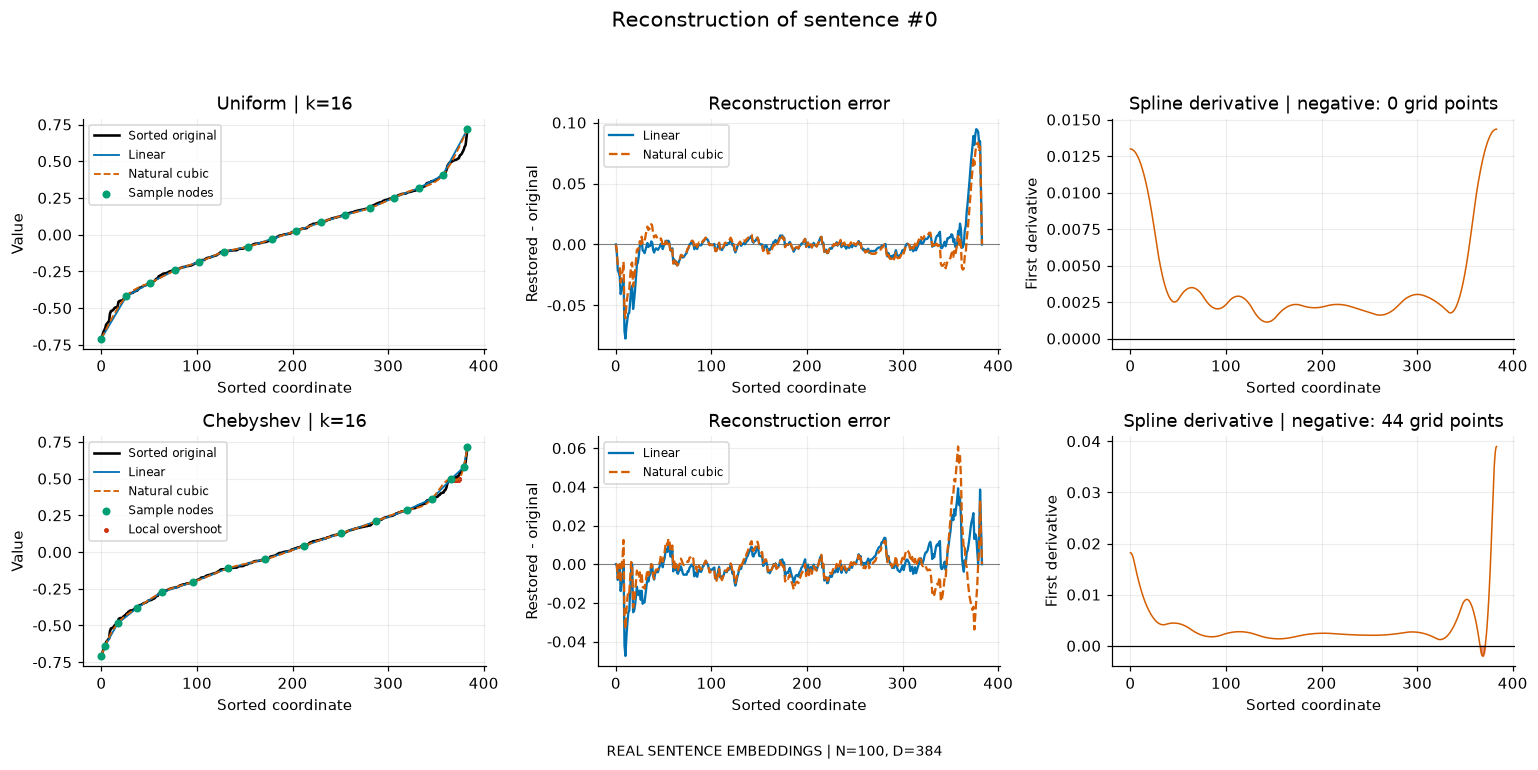

In [7]:
def save_figure(fig, filename):
    # 각 그림에 데이터 출처를 남겨 합성 테스트의 오인용을 막는다.
    fig.text(0.5, 0.012, f"{DATA_LABEL} | N={N_SENTENCES}, D={DIM}", ha="center", fontsize=9)
    fig.tight_layout(rect=(0, 0.045, 1, 0.94))
    fig.savefig(RESULTS_DIR / filename, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

assert 0 <= SELECTED_SENTENCE_INDEX < N_SENTENCES
vis_count = min(max(2, VIS_SAMPLE_COUNT), DIM)
original_sorted = sorted_embeddings[SELECTED_SENTENCE_INDEX].astype(np.float64)
grid = np.arange(DIM)
dense_grid = np.linspace(0, DIM - 1, max(1000, 8 * DIM))
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for row, sampling in enumerate(SAMPLING_METHODS):
    idx = SAMPLERS[sampling](DIM, vis_count)
    values = original_sorted[idx]
    linear = linear_interpolation(idx, values, DIM)
    spline = CubicSpline(idx, values, bc_type="natural", extrapolate=False)
    cubic = spline(grid)
    dense_values = spline(dense_grid)
    interval = np.clip(np.searchsorted(idx, dense_grid, side="right") - 1, 0, len(idx) - 2)
    outside = ((dense_values < values[interval] - 1e-10)
               | (dense_values > values[interval + 1] + 1e-10))
    ax = axes[row, 0]
    ax.plot(grid, original_sorted, color="black", lw=1.7, label="Sorted original")
    ax.plot(grid, linear, color="#0072B2", lw=1.2, label="Linear")
    ax.plot(dense_grid, dense_values, color="#D55E00", ls="--", lw=1.2, label="Natural cubic")
    ax.scatter(idx, values, color="#009E73", s=18, zorder=5, label="Sample nodes")
    if outside.any():
        ax.scatter(dense_grid[outside], dense_values[outside], color="#CC3311", s=5, label="Local overshoot")
    ax.set(title=f"{sampling.title()} | k={vis_count}", xlabel="Sorted coordinate", ylabel="Value")
    ax.legend(fontsize=8)
    ax = axes[row, 1]
    ax.axhline(0, color="gray", lw=0.7)
    ax.plot(grid, linear - original_sorted, color="#0072B2", label="Linear")
    ax.plot(grid, cubic - original_sorted, color="#D55E00", ls="--", label="Natural cubic")
    ax.set(title="Reconstruction error", xlabel="Sorted coordinate", ylabel="Restored - original")
    ax.legend(fontsize=8)
    ax = axes[row, 2]
    derivative = spline(dense_grid, 1)
    ax.plot(dense_grid, derivative, color="#D55E00", lw=1)
    ax.axhline(0, color="black", lw=0.8)
    ax.fill_between(dense_grid, derivative, 0, where=derivative < 0, color="#CC3311", alpha=0.5)
    ax.set(title=f"Spline derivative | negative: {np.count_nonzero(derivative < -1e-10)} grid points",
           xlabel="Sorted coordinate", ylabel="First derivative")
fig.suptitle(f"Reconstruction of sentence #{SELECTED_SENTENCE_INDEX}", fontsize=14)
print("선택한 문장:", sentences[SELECTED_SENTENCE_INDEX])
save_figure(fig, "reconstruction_comparison.png")


## 9. 전체 실험 및 결과 저장
각 조건에서 모든 문장을 복원하고 문장별 지표를 수집한다. 표준편차는 **표본 표준편차(ddof=1)**이다. 정렬된 조건의 overshoot와 단조성 위반은 역정렬 전에 측정한다. 비정렬 대조군에서 단조성 관련 지표는 연구 질문에 해당하지 않아 NaN으로 표시한다.

`results.csv`는 조건별 평균·표준편차, `results_per_sentence.csv`는 개별 측정값이다. 실행 설정·데이터 출처·라이브러리 버전은 `run_metadata.json`에 저장한다. 저장량 평균과 표준편차도 포함하며 같은 조건 내 저장량 표준편차는 0이다.


In [8]:
experiment_started = time.perf_counter()
records = []
conditions = [
    ("sorted", sampling, interpolation)
    for sampling in SAMPLING_METHODS
    for interpolation in INTERPOLATION_METHODS
] + [("original", "uniform", "linear")]

for ordering, sampling, interpolation in conditions:
    is_sorted = ordering == "sorted"
    for count in valid_sample_counts:
        indices = SAMPLERS[sampling](DIM, count)
        for sentence_id, original in enumerate(embeddings):
            values = sorted_embeddings[sentence_id] if is_sorted else original
            sampled_values = values[indices]
            permutation = permutations[sentence_id] if is_sorted else None
            restored_in_order = INTERPOLATORS[interpolation](indices, sampled_values, DIM)
            restored = inverse_sort(restored_in_order, permutation) if is_sorted else restored_in_order
            assert restored.shape == original.shape and np.isfinite(restored).all()
            payload = pack_embedding(indices, sampled_values, DIM, sampling, interpolation, permutation)
            decoded = unpack_embedding(payload)
            np.testing.assert_allclose(decoded, restored, atol=1e-12, rtol=1e-12)
            row = {
                "data_source": data_source,
                "sentence_id": sentence_id,
                "language": "ko" if sentence_id < len(sentences_ko) else "en",
                "ordering": ordering, "sampling": sampling,
                "interpolation": interpolation, "sample_count": count,
                **evaluate_reconstruction(original, restored),
                **storage_metrics(payload, DIM, count, is_sorted),
            }
            if is_sorted:
                row.update(overshoot_metrics(indices, sampled_values, restored_in_order))
            else:
                row.update({name: np.nan for name in [
                    "overshoot_fraction", "max_overshoot", "monotonicity_violations"
                ]})
            records.append(row)

raw_results = pd.DataFrame(records)
group_columns = ["data_source", "ordering", "sampling", "interpolation", "sample_count"]
metric_columns = [
    "cosine", "mse", "mae", "max_abs_error",
    "original_bytes", "sample_value_bytes", "sample_index_bytes", "permutation_bytes",
    "header_bytes", "compressed_bytes", "storage_reduction_pct", "element_reduction_pct",
    "overshoot_fraction", "max_overshoot", "monotonicity_violations",
]
grouped = raw_results.groupby(group_columns, sort=False)
results = grouped[metric_columns].agg(["mean", "std"])
results.columns = ["_".join(parts) for parts in results.columns]
results = results.reset_index()
results["n_sentences"] = grouped.size().to_numpy()
assert len(results) == len(conditions) * len(valid_sample_counts)
assert len(raw_results) == len(results) * N_SENTENCES
assert np.isfinite(raw_results[metric_columns[:12]].to_numpy()).all()
assert raw_results.loc[raw_results.ordering == "original", "permutation_bytes"].eq(0).all()
assert raw_results.loc[raw_results.ordering == "sorted", "permutation_bytes"].eq(DIM * INDEX_DTYPE.itemsize).all()
assert results["compressed_bytes_std"].eq(0).all()
raw_results.to_csv(RESULTS_DIR / "results_per_sentence.csv", index=False, encoding="utf-8-sig")
results.to_csv(RESULTS_DIR / "results.csv", index=False, encoding="utf-8-sig")

# 원본과 압축 데이터의 실제 파일 길이로 byte 계산을 교차 검증한다.
demo_count = valid_sample_counts[0]
demo_indices = uniform_sampling(DIM, demo_count)
demo_payload = pack_embedding(
    demo_indices, sorted_embeddings[0, demo_indices], DIM,
    "uniform", "linear", permutations[0],
)
(RESULTS_DIR / "example_compressed.bin").write_bytes(demo_payload)
(RESULTS_DIR / "example_original.bin").write_bytes(embeddings[0].astype("<f4").tobytes())
assert (RESULTS_DIR / "example_compressed.bin").stat().st_size == len(demo_payload)
assert (RESULTS_DIR / "example_original.bin").stat().st_size == 4 * DIM
np.testing.assert_allclose(
    unpack_embedding((RESULTS_DIR / "example_compressed.bin").read_bytes()),
    inverse_sort(linear_interpolation(demo_indices, sorted_embeddings[0, demo_indices], DIM), permutations[0]),
)
experiment_seconds = time.perf_counter() - experiment_started
run_metadata = {
    "timestamp_utc": RUN_TIMESTAMP_UTC, "data_source": data_source,
    "model_name": MODEL_NAME if data_source == "real" else None,
    "model_revision": model_revision if data_source == "real" else None,
    "embedding_cache": str(cache_path) if data_source == "real" else None,
    "sentences": sentences, "random_seed": RANDOM_SEED,
    "shape": list(embeddings.shape), "dtype": str(embeddings.dtype),
    "index_dtype": str(INDEX_DTYPE), "sample_counts": valid_sample_counts,
    "sampling_methods": SAMPLING_METHODS,
    "interpolation_methods": INTERPOLATION_METHODS,
    "normalize_embeddings": NORMALIZE_EMBEDDINGS if data_source == "real" else False,
    "cpu_threads": CPU_THREADS, "batch_size": BATCH_SIZE,
    "versions": PACKAGE_VERSIONS, "std_ddof": 1,
    "storage_format": "EIC1: 16-byte header + float32 samples + explicit indices + optional permutation",
    "embedding_seconds": embedding_seconds, "experiment_seconds": experiment_seconds,
}
(RESULTS_DIR / "run_metadata.json").write_text(
    json.dumps(run_metadata, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"{len(results)}개 조건, {len(raw_results)}개 문장별 측정 | 실험: {experiment_seconds:.2f} s")
display(results)


40개 조건, 4000개 문장별 측정 | 실험: 3.04 s


,data_source,ordering,sampling,interpolation,sample_count,cosine_mean,cosine_std,mse_mean,mse_std,mae_mean,mae_std,max_abs_error_mean,max_abs_error_std,original_bytes_mean,original_bytes_std,sample_value_bytes_mean,sample_value_bytes_std,sample_index_bytes_mean,sample_index_bytes_std,permutation_bytes_mean,permutation_bytes_std,header_bytes_mean,header_bytes_std,compressed_bytes_mean,compressed_bytes_std,storage_reduction_pct_mean,storage_reduction_pct_std,element_reduction_pct_mean,element_reduction_pct_std,overshoot_fraction_mean,overshoot_fraction_std,max_overshoot_mean,max_overshoot_std,monotonicity_violations_mean,monotonicity_violations_std,n_sentences
0,real,sorted,uniform,linear,8,0.989504,5.034930e-03,5.482480e-03,2.844283e-03,0.036731,0.008660,0.232827,0.070013,1536.0,0.0,32.0,0.0,16.0,0.0,768.0,0.0,16.0,0.0,832.0,0.0,45.833333,0.0,97.916667,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
1,real,sorted,uniform,linear,16,0.994413,3.485133e-03,1.483393e-03,9.742037e-04,0.014398,0.003839,0.185298,0.067243,1536.0,0.0,64.0,0.0,32.0,0.0,768.0,0.0,16.0,0.0,880.0,0.0,42.708333,0.0,95.833333,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
2,real,sorted,uniform,linear,32,0.997881,1.619427e-03,3.853026e-04,3.084200e-04,0.006123,0.001566,0.140483,0.062578,1536.0,0.0,128.0,0.0,64.0,0.0,768.0,0.0,16.0,0.0,976.0,0.0,36.458333,0.0,91.666667,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
3,real,sorted,uniform,linear,64,0.999234,7.040743e-04,1.158397e-04,1.113811e-04,0.003123,0.000705,0.101388,0.057411,1536.0,0.0,256.0,0.0,128.0,0.0,768.0,0.0,16.0,0.0,1168.0,0.0,23.958333,0.0,83.333333,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
4,real,sorted,uniform,linear,96,0.999601,3.545692e-04,5.689001e-05,5.345872e-05,0.002166,0.000414,0.082592,0.048307,1536.0,0.0,384.0,0.0,192.0,0.0,768.0,0.0,16.0,0.0,1360.0,0.0,11.458333,0.0,75.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
5,real,sorted,uniform,linear,128,0.999757,2.080608e-04,3.393808e-05,3.132673e-05,0.001625,0.000281,0.068316,0.041467,1536.0,0.0,512.0,0.0,256.0,0.0,768.0,0.0,16.0,0.0,1552.0,0.0,-1.041667,0.0,66.666667,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
6,real,sorted,uniform,linear,192,0.999880,1.051016e-04,1.658344e-05,1.547781e-05,0.001005,0.000181,0.051119,0.033180,1536.0,0.0,768.0,0.0,384.0,0.0,768.0,0.0,16.0,0.0,1936.0,0.0,-26.041667,0.0,50.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
7,real,sorted,uniform,linear,256,0.999901,1.027461e-04,1.367369e-05,1.499713e-05,0.000697,0.000146,0.049867,0.033710,1536.0,0.0,1024.0,0.0,512.0,0.0,768.0,0.0,16.0,0.0,2320.0,0.0,-51.041667,0.0,33.333333,0.0,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,100
8,real,sorted,uniform,cubic_spline,8,0.989114,5.130187e-03,3.948306e-03,2.181670e-03,0.032762,0.008173,0.215515,0.069039,1536.0,0.0,32.0,0.0,16.0,0.0,768.0,0.0,16.0,0.0,832.0,0.0,45.833333,0.0,97.916667,0.0,0.000521,0.005208,0.000029,0.000293,0.28,2.015496,100
9,real,sorted,uniform,cubic_spline,16,0.995019,3.211976e-03,1.059236e-03,7.501631e-04,0.012714,0.003602,0.170335,0.066064,1536.0,0.0,64.0,0.0,32.0,0.0,768.0,0.0,16.0,0.0,880.0,0.0,42.708333,0.0,95.833333,0.0,0.000365,0.003646,0.000051,0.000514,0.10,1.000000,100


## 10. 샘플 수와 코사인 유사도
선은 평균, 음영은 문장 간 ±1 표준편차이다. 대조군은 회색 점선으로 표시한다. 전체 범위와 높은 정확도 구간을 함께 보여 주며 확대 패널 밖의 값도 왼쪽 패널에서 확인할 수 있다.

샘플 수 축은 log2 척도로 표시하되 각 눈금에는 실제 k를 적는다. 확대 범위는 정렬 조건의 관측값으로 정한다.

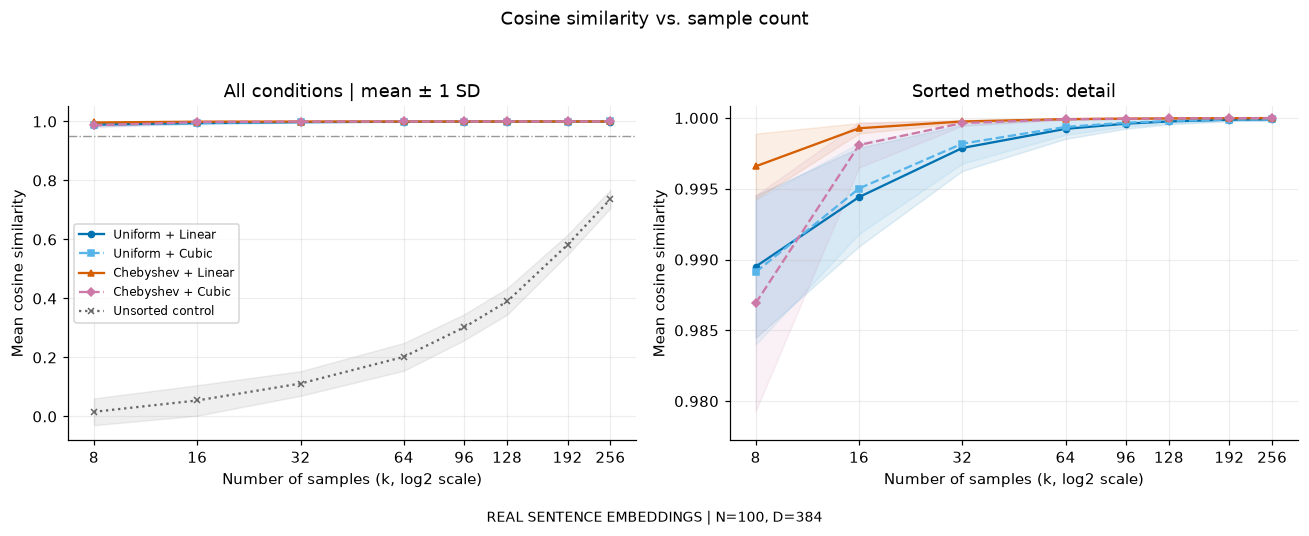

In [9]:
SERIES_STYLES = {
    ("sorted", "uniform", "linear"): ("Uniform + Linear", "#0072B2", "-", "o"),
    ("sorted", "uniform", "cubic_spline"): ("Uniform + Cubic", "#56B4E9", "--", "s"),
    ("sorted", "chebyshev", "linear"): ("Chebyshev + Linear", "#D55E00", "-", "^"),
    ("sorted", "chebyshev", "cubic_spline"): ("Chebyshev + Cubic", "#CC79A7", "--", "D"),
    ("original", "uniform", "linear"): ("Unsorted control", "#666666", ":", "x"),
}

def result_series():
    # 모든 그림에서 범례 순서와 색을 동일하게 유지한다.
    for key, style in SERIES_STYLES.items():
        ordering, sampling, interpolation = key
        frame = results[
            (results.ordering == ordering) & (results.sampling == sampling)
            & (results.interpolation == interpolation)
        ].sort_values("sample_count")
        if not frame.empty:
            yield key, style, frame

def plot_metric(ax, metric, ylabel, show_std=True):
    for _, (label, color, linestyle, marker), frame in result_series():
        x = frame.sample_count.to_numpy()
        mean = frame[f"{metric}_mean"].to_numpy()
        std = frame[f"{metric}_std"].to_numpy()
        ax.plot(x, mean, color=color, ls=linestyle, marker=marker, ms=4, lw=1.5, label=label)
        if show_std:
            ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.10)
    ax.set(xlabel="Number of samples (k, log2 scale)", ylabel=ylabel)
    ax.set_xscale("log", base=2)
    ax.set_xticks(valid_sample_counts, labels=[str(k) for k in valid_sample_counts])
    ax.xaxis.set_minor_locator(NullLocator())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax in axes:
    plot_metric(ax, "cosine", "Mean cosine similarity")
    ax.axhline(COSINE_TARGET, color="#999999", ls="-.", lw=0.9)
axes[0].set_title("All conditions | mean ± 1 SD")
zoom_frame = results[results.ordering == "sorted"]
zoom_min = float((zoom_frame.cosine_mean - zoom_frame.cosine_std).min())
zoom_span = max(1e-4, 1 - zoom_min)
zoom_limits = (max(-1, zoom_min - 0.1 * zoom_span), 1 + 0.04 * zoom_span)
axes[1].set(title="Sorted methods: detail", ylim=zoom_limits)
axes[0].legend(fontsize=8)
fig.suptitle("Cosine similarity vs. sample count")
save_figure(fig, "cosine_vs_samples.png")


## 11. 샘플 수와 MSE / MAE
주 실험과 대조군의 오차 크기 차이를 읽을 수 있도록 0도 표현 가능한 symlog 축을 사용한다. 음영은 평균±표준편차의 관찰 변동 폭이며 음수가 될 수 있는 하한은 오차의 정의역인 0에서 자른다.


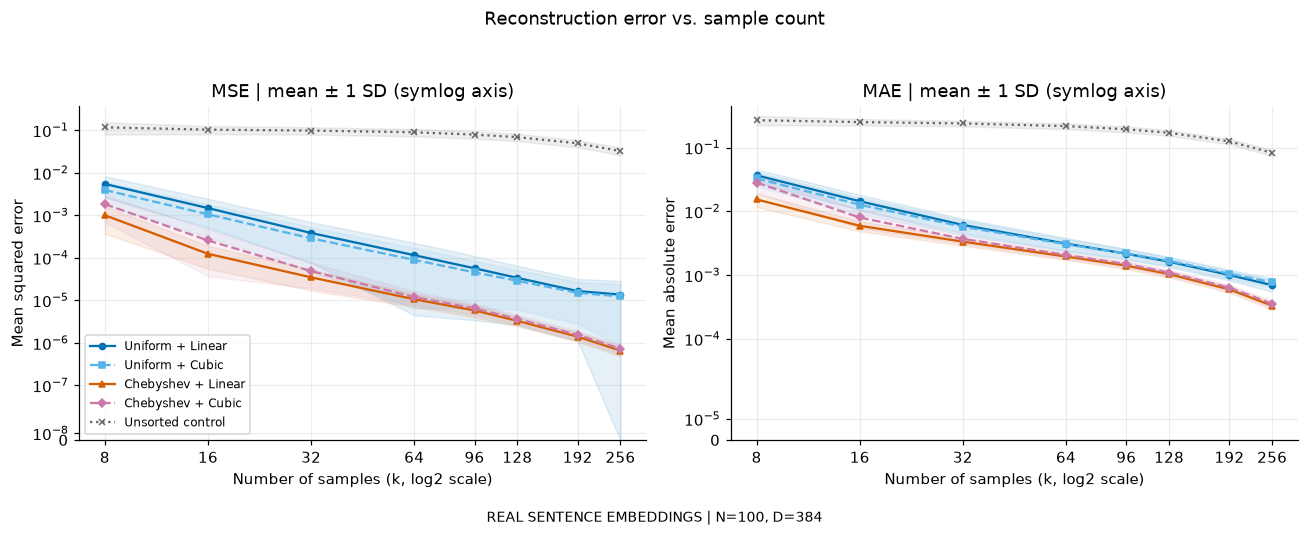

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, metric, title in zip(axes, ["mse", "mae"], ["Mean squared error", "Mean absolute error"]):
    plot_metric(ax, metric, title, show_std=False)
    for _, (_, color, _, _), frame in result_series():
        mean = frame[f"{metric}_mean"].to_numpy()
        std = frame[f"{metric}_std"].to_numpy()
        ax.fill_between(frame.sample_count.to_numpy(), np.maximum(0, mean - std),
                        mean + std, color=color, alpha=0.10)
    positive_means = results.loc[results[f"{metric}_mean"] > 0, f"{metric}_mean"]
    linear_threshold = max(1e-15, float(positive_means.min()) / 10) if len(positive_means) else 1e-12
    ax.set_yscale("symlog", linthresh=linear_threshold)
    ax.set_title(f"{metric.upper()} | mean ± 1 SD (symlog axis)")
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=8)
fig.suptitle("Reconstruction error vs. sample count")
save_figure(fig, "error_vs_samples.png")


## 12. 샘플 수와 실제 저장량 감소율
주 실험 네 조합의 저장량은 동일한 k에서 같으므로 하나의 선으로 합친다. 순열 비용을 제외한 비정렬 대조군과, 샘플 값 개수만 센 이상적 원소 수 감소율을 구분한다. 오른쪽에는 주 실험의 값·샘플 위치·순열·헤더 비용을 쌓아서 표시한다.


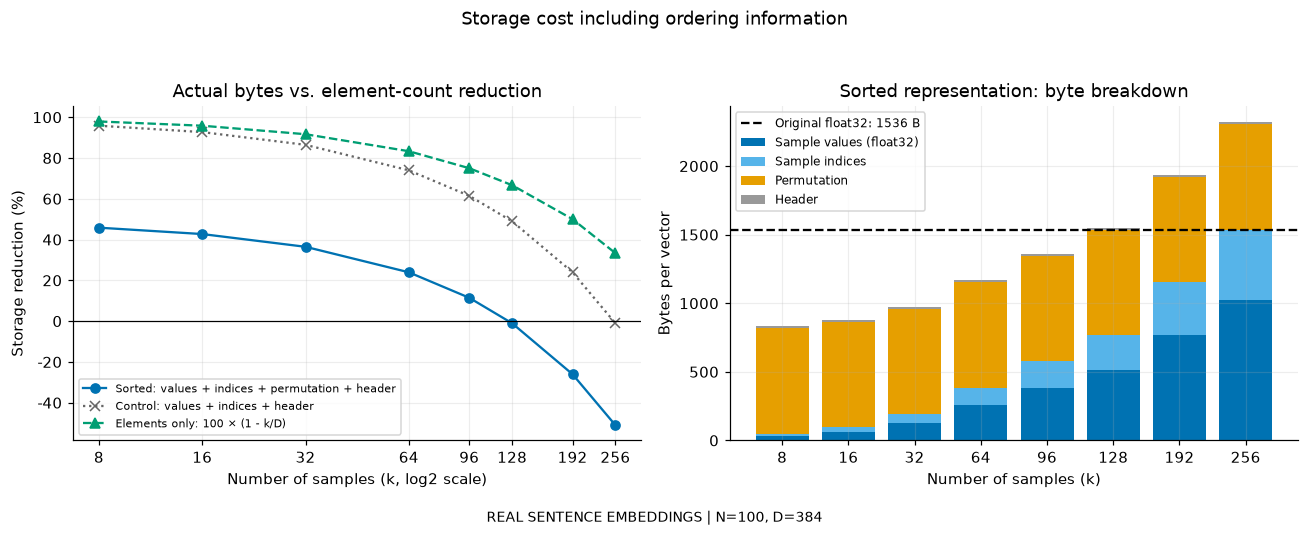

In [11]:
storage_sorted = results[
    (results.ordering == "sorted") & (results.sampling == "uniform")
    & (results.interpolation == "linear")
].sort_values("sample_count")
storage_control = results[results.ordering == "original"].sort_values("sample_count")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
ax.plot(storage_sorted.sample_count, storage_sorted.storage_reduction_pct_mean, "o-",
        color="#0072B2", label="Sorted: values + indices + permutation + header")
ax.plot(storage_control.sample_count, storage_control.storage_reduction_pct_mean, "x:",
        color="#666666", label="Control: values + indices + header")
ax.plot(storage_sorted.sample_count, storage_sorted.element_reduction_pct_mean, "^--",
        color="#009E73", label="Elements only: 100 × (1 - k/D)")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Number of samples (k, log2 scale)", ylabel="Storage reduction (%)",
       title="Actual bytes vs. element-count reduction")
ax.set_xscale("log", base=2)
ax.set_xticks(valid_sample_counts, labels=[str(k) for k in valid_sample_counts])
ax.xaxis.set_minor_locator(NullLocator())
ax.legend(fontsize=7.5)
ax = axes[1]
positions = np.arange(len(storage_sorted))
bottom = np.zeros(len(storage_sorted))
for metric, label, color in [
    ("sample_value_bytes", "Sample values (float32)", "#0072B2"),
    ("sample_index_bytes", "Sample indices", "#56B4E9"),
    ("permutation_bytes", "Permutation", "#E69F00"),
    ("header_bytes", "Header", "#999999"),
]:
    heights = storage_sorted[f"{metric}_mean"].to_numpy()
    ax.bar(positions, heights, bottom=bottom, label=label, color=color)
    bottom += heights
ax.axhline(4 * DIM, color="black", ls="--", label=f"Original float32: {4 * DIM} B")
ax.set_xticks(positions, storage_sorted.sample_count)
ax.set(xlabel="Number of samples (k)", ylabel="Bytes per vector", title="Sorted representation: byte breakdown")
ax.legend(fontsize=8)
fig.suptitle("Storage cost including ordering information")
save_figure(fig, "compression_vs_samples.png")


## 13. 실제 저장량 감소율과 코사인 유사도
오른쪽일수록 저장량이 적고 위쪽일수록 복원 정확도가 높다. 곡선의 각 점은 시험한 샘플 수 하나이다. 수직 오차 막대는 ±1 표준편차이며 음수 감소율은 저장 공간 증가를 의미한다.


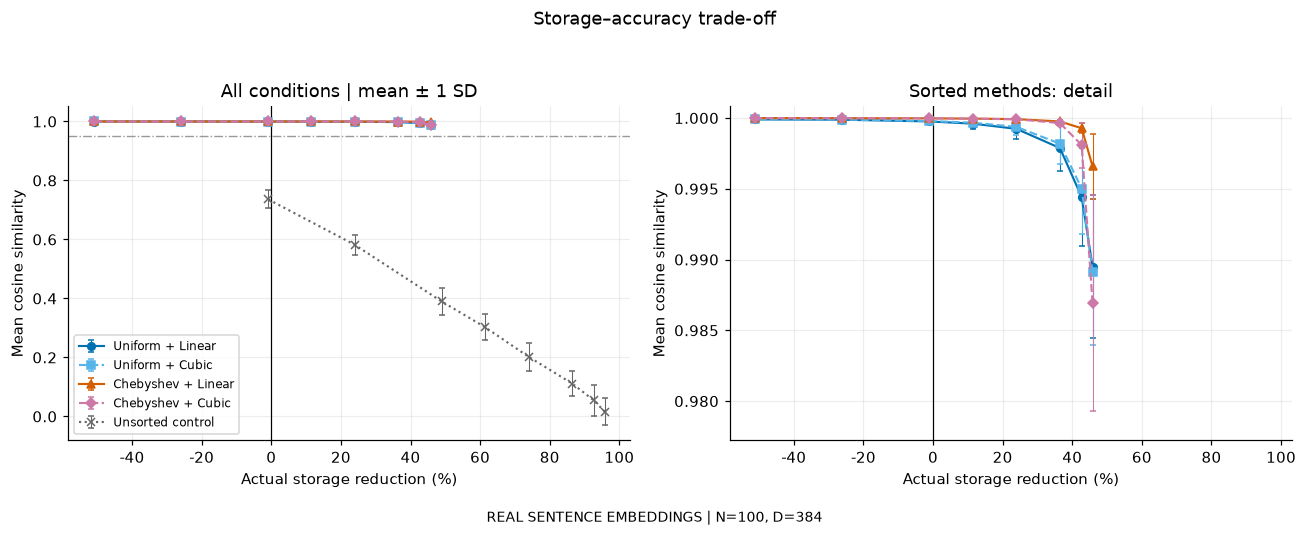

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax in axes:
    for _, (label, color, linestyle, marker), frame in result_series():
        ax.errorbar(
            frame.storage_reduction_pct_mean, frame.cosine_mean, yerr=frame.cosine_std,
            color=color, ls=linestyle, marker=marker, ms=5, lw=1.4,
            capsize=2, elinewidth=0.7, label=label,
        )
    ax.axvline(0, color="black", lw=0.8)
    ax.axhline(COSINE_TARGET, color="#999999", ls="-.", lw=0.9)
    ax.set(xlabel="Actual storage reduction (%)", ylabel="Mean cosine similarity")
axes[0].set_title("All conditions | mean ± 1 SD")
axes[0].legend(fontsize=8, loc="lower left")
axes[1].set(title="Sorted methods: detail", ylim=zoom_limits)
fig.suptitle("Storage–accuracy trade-off")
save_figure(fig, "compression_vs_cosine.png")

## 14. 측정 결과 자동 요약
다음 문장은 위 결과표에서 계산한다. '유리함'은 시험한 문장과 샘플 수에 한정하며, 샘플링/보간 비교는 같은 k에서의 **평균 코사인 유사도**를 주 기준으로 삼는다. MSE는 보조 기준이다. 0.95 기준은 모든 문장의 보장이 아니라 **문장별 코사인 유사도의 평균**이다.

추천 규칙은 먼저 평균 코사인 ≥ 설정한 기준이고 실제 저장량 감소율이 양수인 조건을 남긴 뒤, **저장량 감소율 최대 → 평균 코사인 최대 → 평균 MSE 최소** 순으로 고른다. 통계적 유의성이나 전역 최적성을 주장하지 않는다. 문장 중 기준을 달성한 비율도 별도로 보여 준다.

논문에는 모델/버전, 100문장의 제한된 표본, 정규화 여부, 정수 노드 보정, natural 경계조건, 표준편차 정의, 순열·인덱스·헤더를 포함한 저장 방식을 명시해야 한다. 첫 다운로드와 캐시 실행 시간을 혼동하지 않도록 임베딩 준비 시간과 보간 실험 시간을 구분해 기록한다.


In [13]:
main_results = results[results.ordering == "sorted"].copy()
summary_lines = [
    f"데이터: **{DATA_LABEL}**, {N_SENTENCES}문장 × {DIM}차원.",
    f"시험 조건: 주 실험 {len(main_results)}개 + 비정렬 대조군 {len(results) - len(main_results)}개.",
    "### 1. 샘플 수와 코사인 유사도",
]
for key, (label, _, _, _), frame in result_series():
    values = frame.cosine_mean.to_numpy()
    decreases = int(np.count_nonzero(np.diff(values) < -1e-12))
    summary_lines.append(
        f"- {label}: k={int(frame.iloc[0].sample_count)}의 {values[0]:.6f} → "
        f"k={int(frame.iloc[-1].sample_count)}의 {values[-1]:.6f}; "
        f"인접 샘플 수 사이 평균 감소 {decreases}회."
    )

summary_lines.append("### 2. Chebyshev와 Uniform 비교")
for interpolation in INTERPOLATION_METHODS:
    subset = main_results[main_results.interpolation == interpolation]
    pivot = subset.pivot(index="sample_count", columns="sampling", values="cosine_mean")
    delta = pivot["chebyshev"] - pivot["uniform"]
    mse_pivot = subset.pivot(index="sample_count", columns="sampling", values="mse_mean")
    summary_lines.append(
        f"- {interpolation}: {len(delta)}개 동일 k 비교 중 Chebyshev 우세 "
        f"{int((delta > 1e-12).sum())}회, Uniform 우세 {int((delta < -1e-12).sum())}회, "
        f"동률 {int((delta.abs() <= 1e-12).sum())}회. "
        f"평균 코사인 차이(C−U) {delta.mean():+.6f}; "
        f"평균 MSE 차이 {(mse_pivot.chebyshev - mse_pivot.uniform).mean():+.3e}."
    )

summary_lines.append("### 3. Linear와 Cubic Spline 비교")
for sampling in SAMPLING_METHODS:
    subset = main_results[main_results.sampling == sampling]
    pivot = subset.pivot(index="sample_count", columns="interpolation", values="cosine_mean")
    delta = pivot["cubic_spline"] - pivot["linear"]
    mse_pivot = subset.pivot(index="sample_count", columns="interpolation", values="mse_mean")
    summary_lines.append(
        f"- {sampling}: {len(delta)}개 동일 k 비교 중 Cubic 우세 "
        f"{int((delta > 1e-12).sum())}회, Linear 우세 {int((delta < -1e-12).sum())}회, "
        f"동률 {int((delta.abs() <= 1e-12).sum())}회. "
        f"평균 코사인 차이(Cubic−Linear) {delta.mean():+.6f}; "
        f"평균 MSE 차이 {(mse_pivot.cubic_spline - mse_pivot.linear).mean():+.3e}."
    )

summary_lines.append(f"### 4. 평균 코사인 {COSINE_TARGET:.2f} 이상을 달성한 최소 시험 샘플 수")
for key, (label, _, _, _), frame in result_series():
    eligible = frame[frame.cosine_mean >= COSINE_TARGET]
    if eligible.empty:
        summary_lines.append(f"- {label}: 시험 범위 내 달성 조건 없음.")
    else:
        best = eligible.sort_values("sample_count").iloc[0]
        individual = raw_results[
            (raw_results.ordering == key[0]) & (raw_results.sampling == key[1])
            & (raw_results.interpolation == key[2])
            & (raw_results.sample_count == best.sample_count)
        ]
        pass_fraction = (individual.cosine >= COSINE_TARGET).mean()
        summary_lines.append(
            f"- {label}: k={int(best.sample_count)}, 평균={best.cosine_mean:.6f}, "
            f"SD={best.cosine_std:.6f}, 개별 문장 기준 달성={100 * pass_fraction:.1f}%, "
            f"실제 저장량 감소={best.storage_reduction_pct_mean:.2f}%."
        )

summary_lines.append("### 5. 순열을 포함한 실제 압축 효율")
summary_lines.append(
    f"- 원본 {4 * DIM} B/벡터, 순열 {DIM * INDEX_DTYPE.itemsize} B/벡터 "
    f"({100 * INDEX_DTYPE.itemsize / 4:.1f}% of original), 헤더 {HEADER_BYTES} B/벡터. "
    f"주 실험의 실제 저장량 감소율 범위: "
    f"{main_results.storage_reduction_pct_mean.min():.2f}% ~ "
    f"{main_results.storage_reduction_pct_mean.max():.2f}%."
)
summary_lines.append(
    f"- 저장량이 원본보다 커진 주 실험 조건: "
    f"{int((main_results.storage_reduction_pct_mean < 0).sum())}/{len(main_results)}개."
)
summary_lines.append("### 6. 정확도 기준을 만족하는 저장량 최소 조건")
candidates = results[
    (results.cosine_mean >= COSINE_TARGET) & (results.storage_reduction_pct_mean > 0)
].sort_values(
    ["storage_reduction_pct_mean", "cosine_mean", "mse_mean"],
    ascending=[False, False, True],
)
if candidates.empty:
    summary_lines.append("- 정확도 기준과 양의 실제 저장량 감소율을 동시에 만족하는 시험 조건이 없습니다.")
else:
    best = candidates.iloc[0]
    best_label = SERIES_STYLES[(best.ordering, best.sampling, best.interpolation)][0]
    summary_lines.append(
        f"- 정해 둔 선택 규칙의 추천: **{best_label}, k={int(best.sample_count)}**. "
        f"평균 코사인 {best.cosine_mean:.6f} ± {best.cosine_std:.6f}, "
        f"MSE {best.mse_mean:.3e}, MAE {best.mae_mean:.3e}, "
        f"{int(best.compressed_bytes_mean)} B/벡터, 실제 저장량 감소 "
        f"{best.storage_reduction_pct_mean:.2f}%."
    )

summary_lines.append("### 추가 확인: 정렬 효과와 spline overshoot")
comparison = results[
    ((results.ordering == "sorted") & (results.sampling == "uniform") & (results.interpolation == "linear"))
    | (results.ordering == "original")
].pivot(index="sample_count", columns="ordering", values="cosine_mean")
sorting_gain = comparison["sorted"] - comparison["original"]
summary_lines.append(
    f"- Uniform+Linear의 동일 k 비교에서 정렬 후 평균 코사인이 더 높은 조건은 "
    f"{int((sorting_gain > 1e-12).sum())}/{len(sorting_gain)}개이며, "
    f"평균 차이는 {sorting_gain.mean():+.6f}입니다. 순열 저장 비용도 함께 판단해야 합니다."
)
for sampling in SAMPLING_METHODS:
    cubic_rows = raw_results[
        (raw_results.ordering == "sorted") & (raw_results.sampling == sampling)
        & (raw_results.interpolation == "cubic_spline")
    ]
    overshoot_rate = 100 * (cubic_rows.overshoot_fraction > 0).mean()
    monotone_rate = 100 * (cubic_rows.monotonicity_violations > 0).mean()
    summary_lines.append(
        f"- {sampling} + Cubic: 문장×k 복원 중 정수 격자 국소 overshoot 관찰 "
        f"{overshoot_rate:.1f}%, 단조성 위반 관찰 {monotone_rate:.1f}%; "
        f"관찰 최대 overshoot {cubic_rows.max_overshoot.max():.3e}."
    )
summary_lines.append(
    "- 정수 격자에서 위반이 없더라도 좌표 사이의 연속 spline은 overshoot할 수 있습니다. "
    "Cell 8의 조밀 격자 도함수 그림과 함께 해석하세요."
)
if data_source == "synthetic":
    summary_lines.insert(0, "**합성 데이터 테스트 결과입니다. 문장의 의미적 특성에 대한 결론을 내릴 수 없습니다.**")
display(Markdown("\n\n".join(summary_lines)))

expected_files = [
    "results.csv", "cosine_vs_samples.png", "error_vs_samples.png",
    "compression_vs_samples.png", "compression_vs_cosine.png",
    "reconstruction_comparison.png",
]
assert all((RESULTS_DIR / name).is_file() and (RESULTS_DIR / name).stat().st_size > 0
           for name in expected_files)
print(f"수학적 검증 및 출력 파일 검증 완료. 결과 폴더: {RESULTS_DIR.resolve()}")
print(f"임베딩 준비: {embedding_seconds:.2f} s; 보간 실험: {experiment_seconds:.2f} s; "
      f"전체 셀 실행: {time.perf_counter() - RUN_STARTED:.2f} s")
display(pd.DataFrame({
    "file": expected_files,
    "bytes": [(RESULTS_DIR / name).stat().st_size for name in expected_files],
}))


데이터: **REAL SENTENCE EMBEDDINGS**, 100문장 × 384차원.

시험 조건: 주 실험 32개 + 비정렬 대조군 8개.

### 1. 샘플 수와 코사인 유사도

- Uniform + Linear: k=8의 0.989504 → k=256의 0.999901; 인접 샘플 수 사이 평균 감소 0회.

- Uniform + Cubic: k=8의 0.989114 → k=256의 0.999910; 인접 샘플 수 사이 평균 감소 0회.

- Chebyshev + Linear: k=8의 0.996586 → k=256의 0.999995; 인접 샘플 수 사이 평균 감소 0회.

- Chebyshev + Cubic: k=8의 0.986912 → k=256의 0.999995; 인접 샘플 수 사이 평균 감소 0회.

- Unsorted control: k=8의 0.015617 → k=256의 0.736888; 인접 샘플 수 사이 평균 감소 0회.

### 2. Chebyshev와 Uniform 비교

- linear: 8개 동일 k 비교 중 Chebyshev 우세 8회, Uniform 우세 0회, 동률 0회. 평균 코사인 차이(C−U) +0.001911; 평균 MSE 차이 -8.000e-04.

- cubic_spline: 8개 동일 k 비교 중 Chebyshev 우세 7회, Uniform 우세 1회, 동률 0회. 평균 코사인 차이(C−U) +0.000439; 평균 MSE 차이 -4.149e-04.

### 3. Linear와 Cubic Spline 비교

- uniform: 8개 동일 k 비교 중 Cubic 우세 7회, Linear 우세 1회, 동률 0회. 평균 코사인 차이(Cubic−Linear) +0.000097; 평균 MSE 차이 -2.625e-04.

- chebyshev: 8개 동일 k 비교 중 Cubic 우세 0회, Linear 우세 8회, 동률 0회. 평균 코사인 차이(Cubic−Linear) -0.001374; 평균 MSE 차이 +1.226e-04.

### 4. 평균 코사인 0.95 이상을 달성한 최소 시험 샘플 수

- Uniform + Linear: k=8, 평균=0.989504, SD=0.005035, 개별 문장 기준 달성=100.0%, 실제 저장량 감소=45.83%.

- Uniform + Cubic: k=8, 평균=0.989114, SD=0.005130, 개별 문장 기준 달성=100.0%, 실제 저장량 감소=45.83%.

- Chebyshev + Linear: k=8, 평균=0.996586, SD=0.002311, 개별 문장 기준 달성=100.0%, 실제 저장량 감소=45.83%.

- Chebyshev + Cubic: k=8, 평균=0.986912, SD=0.007616, 개별 문장 기준 달성=100.0%, 실제 저장량 감소=45.83%.

- Unsorted control: 시험 범위 내 달성 조건 없음.

### 5. 순열을 포함한 실제 압축 효율

- 원본 1536 B/벡터, 순열 768 B/벡터 (50.0% of original), 헤더 16 B/벡터. 주 실험의 실제 저장량 감소율 범위: -51.04% ~ 45.83%.

- 저장량이 원본보다 커진 주 실험 조건: 12/32개.

### 6. 정확도 기준을 만족하는 저장량 최소 조건

- 정해 둔 선택 규칙의 추천: **Chebyshev + Linear, k=8**. 평균 코사인 0.996586 ± 0.002311, MSE 1.007e-03, MAE 1.539e-02, 832 B/벡터, 실제 저장량 감소 45.83%.

### 추가 확인: 정렬 효과와 spline overshoot

- Uniform+Linear의 동일 k 비교에서 정렬 후 평균 코사인이 더 높은 조건은 8/8개이며, 평균 차이는 +0.698238입니다. 순열 저장 비용도 함께 판단해야 합니다.

- uniform + Cubic: 문장×k 복원 중 정수 격자 국소 overshoot 관찰 49.2%, 단조성 위반 관찰 52.6%; 관찰 최대 overshoot 2.478e-02.

- chebyshev + Cubic: 문장×k 복원 중 정수 격자 국소 overshoot 관찰 71.0%, 단조성 위반 관찰 74.8%; 관찰 최대 overshoot 1.245e-01.

- 정수 격자에서 위반이 없더라도 좌표 사이의 연속 spline은 overshoot할 수 있습니다. Cell 8의 조밀 격자 도함수 그림과 함께 해석하세요.

수학적 검증 및 출력 파일 검증 완료. 결과 폴더: C:\Users\khyun\Projects\vector_compression\results
임베딩 준비: 0.00 s; 보간 실험: 3.04 s; 전체 셀 실행: 10.87 s


,file,bytes
0,results.csv,15044
1,cosine_vs_samples.png,329760
2,error_vs_samples.png,492623
3,compression_vs_samples.png,276568
4,compression_vs_cosine.png,224930
5,reconstruction_comparison.png,593680
